## HW: outliers answers

**Station:** Ashalim, 10 days of January 2024 (5 to 14 January), with `seed = 123`.

## Import data and basic processing

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# settings for all the graphs: resolution, and no lines on the top and right of the axes
plt.rcParams.update({'figure.dpi': 110,
                     'axes.spines.top': False,
                     'axes.spines.right': False})

def day_axis(ax):
    """show the day and the month on the horizontal axis"""
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))

In [2]:
filename = "ashalim_2024.csv"

# the IMS writes '-' where there is no measurement
df = pd.read_csv(filename, na_values=['-'])

# the IMS column that holds the time starts with "Date & Time"
time_column = [c for c in df.columns if c.startswith('Date & Time')][0]

# turn the text into datetimes (the day comes first!) and use them as the index
df['date'] = pd.to_datetime(df[time_column], dayfirst=True)
df = df.set_index('date')

# shorter names for the columns we will use
df = df.rename(columns={'Temperature (°C)': 'temperature',
                        'Rainfall (mm)': 'rain',
                        'Relative humidity (%)': 'humidity',
                        'Global radiation (W/m^2)': 'radiation'})

In [3]:
# 10 consecutive days, with clear daily cycles
start = '2024-01-05'
end = '2024-01-14'
temp_original = df.loc[start:end, 'temperature']

# no gaps: 10 days with a record every 10 minutes have 1440 records
print("records:", len(temp_original), " | missing values (NaN):", temp_original.isna().sum())

records: 1440  | missing values (NaN): 0


The problems are added with the function of the template, and two more functions help us (`conseq_series`, from the challenge, and `score`).

In [4]:
def corrupt(series, seed):
    rng = np.random.default_rng(seed)
    n = len(series)
    bad = series.copy()
    truth = pd.DataFrame(False, index=series.index, columns=['spike', 'no_data', 'stuck'])
    # a sensor stuck for 40 points (a bit more than 6 hours)
    start = rng.integers(100, n - 200)
    bad.iloc[start:start + 40] = bad.iloc[start]
    truth.iloc[start:start + 40, 2] = True
    # 15 other random points, away from the stuck sensor: 12 spikes and 3 codes of "no data"
    free = np.setdiff1d(np.arange(50, n - 50), np.arange(start - 5, start + 46))
    picks = rng.choice(free, size=15, replace=False)
    spikes, no_data = picks[:12], picks[12:]
    bad.iloc[spikes] += rng.choice([-1, 1], size=12) * rng.uniform(1, 2.5, size=12) * series.std()
    truth.iloc[spikes, 0] = True
    bad.iloc[no_data] = -9999
    truth.iloc[no_data, 1] = True
    return bad, truth

seed = 123
temp_bad, truth = corrupt(temp_original, seed)

def conseq_series(series, N):
    # from the challenge: NaN where there are N or more equal values in a row
    sumsum_series = (series.diff() != 0).astype('int').cumsum()
    mask_outliers = series.groupby(sumsum_series).transform('count').ge(N)
    return pd.Series(np.where(mask_outliers, np.nan, series), index=series.index)

def score(found):
    """found = True where your method says there is an outlier"""
    spikes_found = (found & truth['spike']).sum()
    spikes_missed = (~found & truth['spike']).sum()
    false_alarms = (found & ~truth['spike'] & temp_clean.notna()).sum()
    return spikes_found, spikes_missed, false_alarms

## Part 1: common sense first

### The series with the problems

**My prediction:** the three codes of -9999 will dominate the graph and squash the real temperature into a thin line at the top. If I limit the vertical axis I should see the spikes as thin lines, but I expect to miss the ones in the middle of a daily rise or fall.

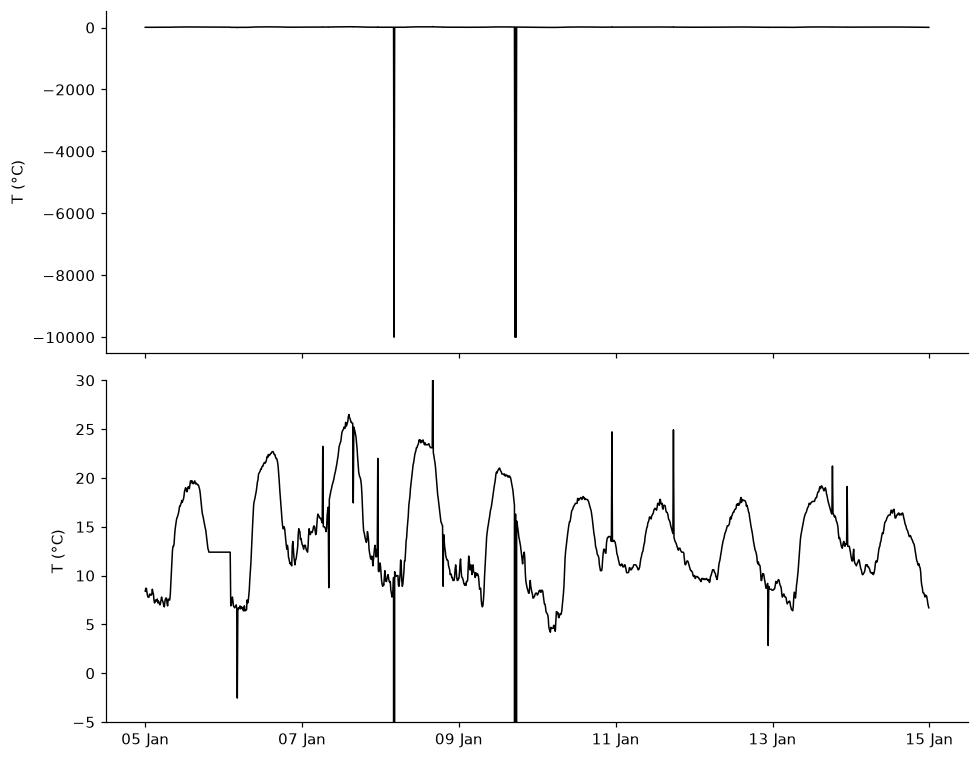

In [5]:
# the series with the problems, as it is, and with the vertical axis limited to realistic temperatures
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(9, 7))
axes[0].plot(temp_bad, color='black', lw=1)
axes[1].plot(temp_bad, color='black', lw=1)
axes[1].set(ylim=[-5, 30])
for ax in axes:
    ax.set_ylabel('T (°C)')
day_axis(axes[1])
fig.tight_layout()

**What I found, and why:** The three -9999 stretch the vertical axis to 10,000, and the real series becomes a flat line at the top. With the axis limited I can see the stuck sensor (the flat line on the evening of 5 January) and most of the spikes, but the small ones, in the middle of a rise or a fall, are easy to miss.

### Common sense checks

In [6]:
# 1. physically impossible values: True where the temperature is outside -30 to 60 °C
nodata = ~temp_bad.between(-30, 60)

# 2. the stuck sensor: 20 or more equal values in a row (the codes of no data are left out)
plateaus = conseq_series(temp_bad.mask(nodata), 20)
stuck = plateaus.isna() & temp_bad.mask(nodata).notna()

# 3. a series without these two problems
temp_clean = temp_bad.mask(nodata | stuck)

print(f"temp_bad:   mean {temp_bad.mean():8.1f} °C, std {temp_bad.std():7.1f} °C")
print(f"temp_clean: mean {temp_clean.mean():8.1f} °C, std {temp_clean.std():7.1f} °C")

# what would the Z-score method find in temp_bad, before the common sense checks?
z_bad = (temp_bad - temp_bad.mean()).abs() / temp_bad.std() > 3
print(f"\nZ-score on temp_bad: {z_bad.sum()} points found, {(z_bad & truth['no_data']).sum()} of them are codes of no data, {(z_bad & truth['spike']).sum()} are spikes")

# how many problems did the common sense checks find?
print(f"\ncodes of no data found: {(nodata & truth['no_data']).sum()} of {truth['no_data'].sum()}")
print(f"stuck sensor found: {(stuck & truth['stuck']).sum()} of {truth['stuck'].sum()} points, with {(stuck & ~truth['stuck']).sum()} false alarms")

temp_bad:   mean     -7.1 °C, std   456.7 °C
temp_clean: mean     13.8 °C, std     4.8 °C

Z-score on temp_bad: 3 points found, 3 of them are codes of no data, 0 are spikes

codes of no data found: 3 of 3
stuck sensor found: 40 of 40 points, with 0 false alarms


**What I found, and why:** With the codes, the mean is -7.1 °C and the standard deviation 457 °C (without them: 13.8 and 4.8 °C). The Z-score method on `temp_bad` finds only the 3 codes and no spike, because the standard deviation became enormous. The common sense checks found all 3 codes and all 40 stuck points, with no false alarms. First remove what is impossible, and only then use statistics.

## Part 2: global methods

**My prediction:** the thresholds will be far from the data, because the daily cycle makes the standard deviation large. The spikes are only 1 to 2.5 standard deviations away, so I expect the two methods to find very few of the 12 spikes, maybe 1 to 3, those at the extremes of the series.

Z-score: (np.int64(2), np.int64(10), np.int64(0))
IQR:     (np.int64(2), np.int64(10), np.int64(0))


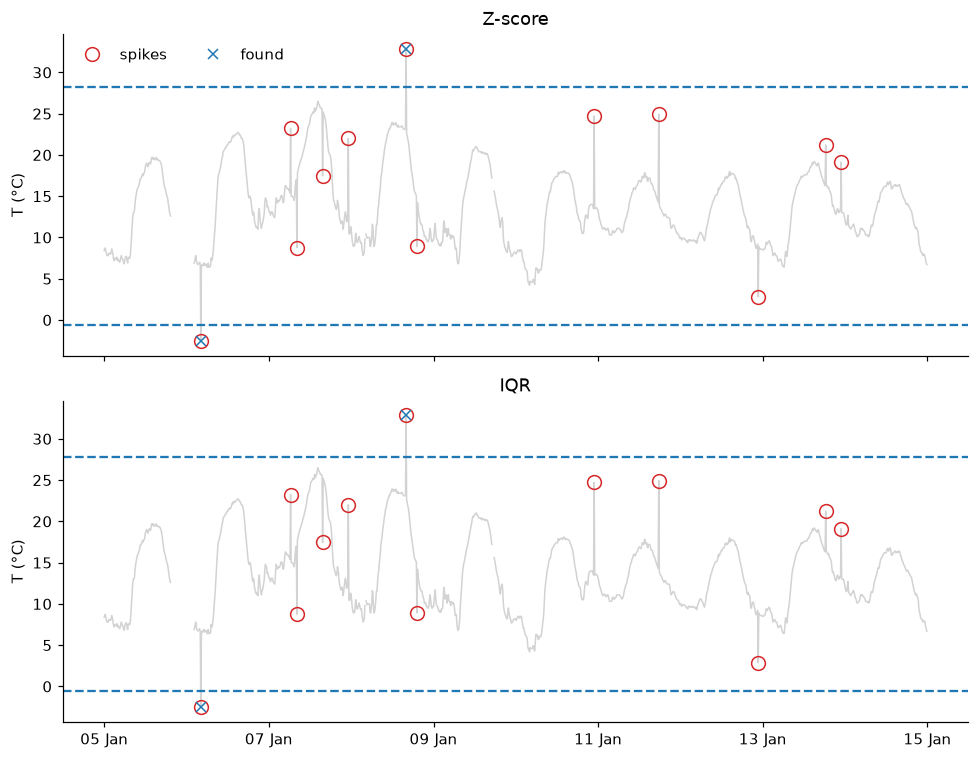

In [7]:
# global Z-score (threshold 3) and global IQR (1.5), using the whole series
mean, std = temp_clean.mean(), temp_clean.std()
found_z = (temp_clean - mean).abs() / std > 3

q1, q3 = temp_clean.quantile(0.25), temp_clean.quantile(0.75)
lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
found_iqr = (temp_clean < lower) | (temp_clean > upper)

# the series, the thresholds, the true spikes (red circles) and the points found (blue crosses)
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(9, 7))
for ax, found, name, limits in zip(axes, [found_z, found_iqr], ['Z-score', 'IQR'],
                                   [(mean - 3 * std, mean + 3 * std), (lower, upper)]):
    ax.plot(temp_clean, color='lightgray', lw=1)
    for limit in limits:
        ax.axhline(limit, color='tab:blue', ls='--')
    ax.plot(temp_clean[truth['spike']], 'o', mfc='none', mec='tab:red', ms=9, label='spikes')
    ax.plot(temp_clean[found], 'x', color='tab:blue', label='found')
    ax.set(ylabel='T (°C)', title=name)
axes[0].legend(frameon=False, ncol=2, loc='upper left')
day_axis(axes[1])
fig.tight_layout()

# spikes found, spikes missed, false alarms
print("Z-score:", score(found_z))
print("IQR:    ", score(found_iqr))

**What I found, and why:** I was right: both methods found only 2 of the 12 spikes, with no false alarms. The thresholds are far from most of the data, because the temperature goes up and down every day, which makes the standard deviation and the IQR large. A spike of 1 to 2.5 standard deviations is, most of the time, inside the normal range of the whole series. This series is non-stationary, and a threshold that does not follow it cannot work.

## Part 3: sliding windows

In [8]:
# the three functions: True where there is an outlier, with centered windows
def rolling_zscore_outliers(series, window, k=3):
    r = series.rolling(window, center=True, min_periods=1)
    return (series - r.mean()).abs() > k * r.std()

def rolling_iqr_outliers(series, window, k=1.5):
    r = series.rolling(window, center=True, min_periods=1)
    q1, q3 = r.quantile(0.25), r.quantile(0.75)
    return (series < q1 - k * (q3 - q1)) | (series > q3 + k * (q3 - q1))

def mad(x):
    return np.median(np.abs(x - np.median(x)))

def rolling_mad_outliers(series, window, k=3):
    r = series.rolling(window, center=True, min_periods=1)
    # 1.4826 scales the MAD to the standard deviation of gaussian data
    return (series - r.median()).abs() > k * 1.4826 * r.apply(mad, raw=True)

### Using them, with a window of 19 points

**My prediction:** the MAD method will find the most spikes, because the median and the MAD are not affected by the spike. The Z-score method will find the fewest, because a spike makes its own standard deviation larger, but it will have few false alarms. The IQR and MAD methods will have more false alarms, since they are stricter about the normal variation.

Z-score  (found, missed, false alarms): (np.int64(10), np.int64(2), np.int64(0))
IQR      (found, missed, false alarms): (np.int64(11), np.int64(1), np.int64(3))
MAD      (found, missed, false alarms): (np.int64(10), np.int64(2), np.int64(2))

MAD on temp_bad finds 0 of the 40 stuck points


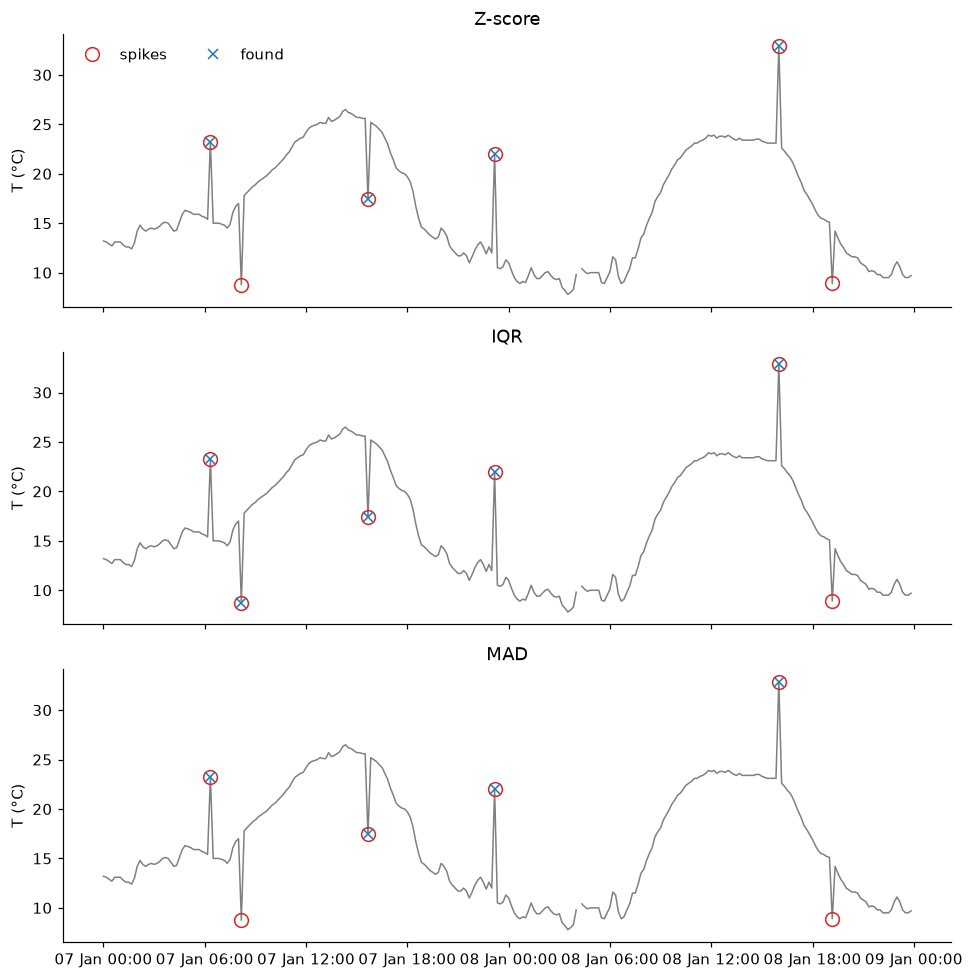

In [9]:
window = 19   # points, about 3 hours
methods = {'Z-score': rolling_zscore_outliers(temp_clean, window, 3),
           'IQR': rolling_iqr_outliers(temp_clean, window, 1.5),
           'MAD': rolling_mad_outliers(temp_clean, window, 3)}

# the two days with the most spikes
spikes_per_day = truth['spike'].resample('D').sum()
last_day = spikes_per_day.rolling(2).sum().idxmax()
zoom = slice(last_day - pd.Timedelta(days=1), last_day + pd.Timedelta(hours=23, minutes=50))

# data (gray), true spikes (red circles) and points found (blue crosses)
fig, axes = plt.subplots(3, 1, sharex=True, figsize=(9, 9))
for ax, (name, found) in zip(axes, methods.items()):
    ax.plot(temp_clean.loc[zoom], color='gray', lw=1)
    ax.plot(temp_clean.loc[zoom][truth['spike'].loc[zoom]], 'o', mfc='none', mec='tab:red', ms=9, label='spikes')
    ax.plot(temp_clean.loc[zoom][found.loc[zoom]], 'x', color='tab:blue', label='found')
    ax.set(ylabel='T (°C)', title=name)
axes[0].legend(frameon=False, ncol=2, loc='upper left')
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%d %b %H:%M'))
fig.tight_layout()

for name, found in methods.items():
    print(f"{name:8s} (found, missed, false alarms): {score(found)}")

# did a sliding method find the stuck sensor? (that part of the series is NaN in temp_clean, so look in temp_bad)
print("\nMAD on temp_bad finds", rolling_mad_outliers(temp_bad.mask(nodata), window, 3)[truth['stuck']].sum(), "of the 40 stuck points")

**What I found, and why:** I was partly wrong. The three methods found about the same, 10 to 11 spikes of 12, and the MAD did not beat the Z-score, which had no false alarms (IQR 3, MAD 2). The spikes that were missed are in the middle of a fast rise or fall (like 08:10 on 7 January), where the window has a big range and the thresholds are wide. No method found the stuck sensor: constant values are not unusual, so we need another detector (`conseq_series`).

### What if... the window and the thresholds change?

**My prediction:** a very short window will fail, because the spike is a big part of its own window. A very long window will also fail, because the daily cycle fills the window and the thresholds become too wide. I expect the best results with the window of 19 points, and a stricter threshold to give fewer false alarms and more misses.

In [10]:
# three windows and three thresholds for each method
settings = {'Z-score': (rolling_zscore_outliers, [2, 3, 5]),
            'IQR': (rolling_iqr_outliers, [1.5, 3, 5]),
            'MAD': (rolling_mad_outliers, [3, 5, 8])}
rows = []
for name, (function, thresholds) in settings.items():
    for window in [5, 19, 73]:
        for k in thresholds:
            found, missed, false_alarms = score(function(temp_clean, window, k))
            rows.append({'method': name, 'window': window, 'k': k,
                         'found': found, 'missed': missed, 'false alarms': false_alarms})
table = pd.DataFrame(rows)

# in each cell: spikes found / spikes missed / false alarms
table['result'] = table['found'].astype(str) + ' / ' + table['missed'].astype(str) + ' / ' + table['false alarms'].astype(str)
table.pivot(index=['method', 'k'], columns='window', values='result')

window                5           19          73
method  k                                       
IQR     1.5  12 / 0 / 27  11 / 1 / 3   5 / 7 / 0
        3.0  11 / 1 / 19  10 / 2 / 1  1 / 11 / 0
        5.0  10 / 2 / 15   7 / 5 / 0  0 / 12 / 0
MAD     3.0  12 / 0 / 45  10 / 2 / 2   3 / 9 / 0
        5.0  10 / 2 / 39  10 / 2 / 0  1 / 11 / 0
        8.0   9 / 3 / 39   6 / 6 / 0  0 / 12 / 0
Z-score 2.0   0 / 12 / 0  12 / 0 / 4   9 / 3 / 4
        3.0   0 / 12 / 0  10 / 2 / 0  2 / 10 / 0
        5.0   0 / 12 / 0  0 / 12 / 0  1 / 11 / 0

**What I found, and why:** A very short window is a surprise. With 5 points the Z-score finds nothing, whatever the threshold: a point cannot be more than 1.8 standard deviations away from a mean that includes itself. The IQR and the MAD find 9 to 12 spikes, but with 15 to 45 false alarms. A very long window (73 points) finds few, because the daily cycle fills it and the thresholds are wide. A stricter threshold means fewer false alarms and more misses. No setting finds all 12 spikes with no false alarms.

## Part 4: repair

**My prediction:** the spikes that were found and the codes of no data are one point each, so linear interpolation will repair them almost perfectly. The stuck sensor is a gap of more than 6 hours, so it will be worse. The spikes that were missed are still there, so they will have the largest error.

spikes found and codes of no data: 0.13 °C
spikes missed:                     7.37 °C
stuck sensor:                      0.54 °C


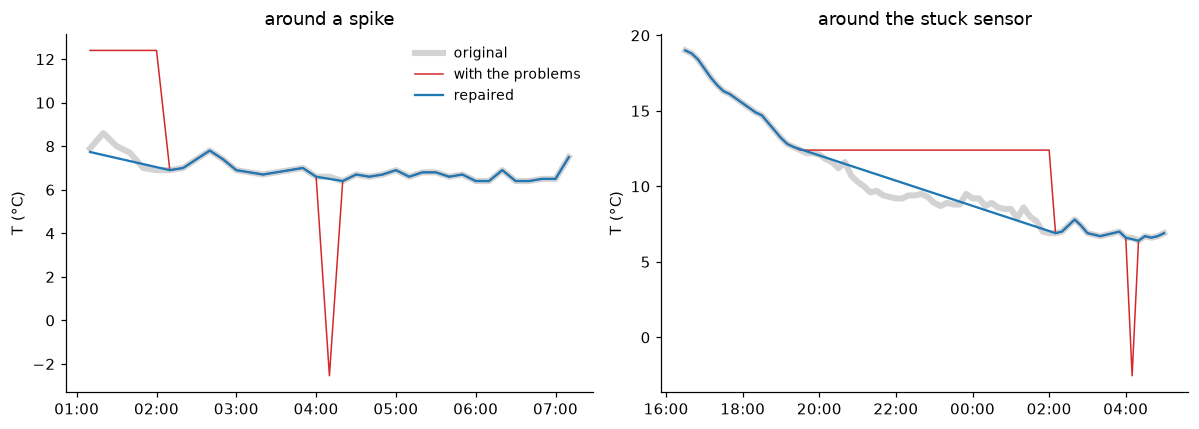

In [11]:
# NaN where the best method found a problem (and the codes and the stuck sensor), then linear interpolation
found = rolling_mad_outliers(temp_clean, 19, 3)
temp_repaired = temp_clean.mask(found).interpolate()

# the mean absolute error, in three places
error = (temp_repaired - temp_original).abs()
print(f"spikes found and codes of no data: {error[(truth['spike'] & found) | truth['no_data']].mean():.2f} °C")
print(f"spikes missed:                     {error[truth['spike'] & ~found].mean():.2f} °C")
print(f"stuck sensor:                      {error[truth['stuck']].mean():.2f} °C")

# the original (gray), the series with the problems (red) and the repaired series (blue), around a spike that was found and around the stuck sensor
spike_time = truth.index[truth['spike'] & found][0]
stuck_times = truth.index[truth['stuck']]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (t0, t1), title in zip(axes, [(spike_time - pd.Timedelta(hours=3), spike_time + pd.Timedelta(hours=3)),
                                      (stuck_times[0] - pd.Timedelta(hours=3), stuck_times[-1] + pd.Timedelta(hours=3))],
                               ['around a spike', 'around the stuck sensor']):
    ax.plot(temp_original.loc[t0:t1], color='lightgray', lw=4, label='original')
    ax.plot(temp_bad.loc[t0:t1].where(lambda s: s > -100), color='tab:red', lw=1, label='with the problems')
    ax.plot(temp_repaired.loc[t0:t1], color='tab:blue', lw=1.5, label='repaired')
    ax.set(title=title, ylabel='T (°C)')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
axes[0].legend(frameon=False, fontsize=9)
fig.tight_layout()

**What I found, and why:** The error is 0.13 °C at the spikes that we found and the codes, 0.54 °C at the stuck sensor, and 7.4 °C at the spikes that we missed. One point is easy to fill, because its neighbors are close. The missed spikes stay as they were: the repair is only as good as the detection. The stuck sensor is a gap of 6.5 hours, and the straight line cannot know what happened inside. The error is small here because it got stuck at night, when the temperature changes slowly. In a morning rise it would be much worse.

## Part 5: think like in the exam

**1. Global thresholds.**

![](outliers-question-A.png){width="85%"}

The method finds B and C, which are outside the thresholds. A and D are inside the band, because the daily cycle makes the standard deviation large and the thresholds far from the data. A sliding method has thresholds that follow the series, a narrow band around the data at each moment, and compares each spike only with its neighbors. It would find all four.

**2. The sliding MAD envelope.**

![](outliers-question-B.png){width="85%"}

At night on 2 to 3 January the temperature is almost constant, so the MAD is small and the band is narrow: even a spike of 3 °C would be found. On 5 January the temperature changes fast, so the window has a large range and the band is wide (about 16 °C): a spike of 3 °C would be missed. The other flagged points are not necessarily errors of the method: they are fast, real changes where the band is narrow. The method finds what is unusual, not only what is wrong.

**3. The 10,000 gaussian numbers.**

In a gaussian distribution, 0.27% of the points are farther than 3 standard deviations just by chance, so about 27 of the 10,000. They are perfectly good data, and the colleague threw them away. An outlier is a point that comes from another distribution, and a large Z-score alone does not tell us that.

**4. A spike, a sliding mean and a sliding median.**

The sliding mean spreads the spike: the 5 windows that contain it have a mean of 10/5 = 2, so we get a flat bump of height 2 and width 5. The sliding median stays at 0 everywhere, because the spike is only 1 of the 5 values of a window and never reaches the middle. Before computing a trend I would use the median: the bump of the mean looks like a real event.

**5. 10 years of hourly temperature.**

First, the common sense checks: physical limits, codes like -9999, stuck sensors and impossible jumps. They catch many problems with no statistics. Second, a sliding method like the MAD, with a window longer than the problems but shorter than the time scale of the signal, and a plot of some periods to look for false alarms. Third, decide what to do with each problem, keeping the raw data and a flag of what was changed.

**6. What to do with an outlier.**

I can do nothing, if the point is real (a storm may be the most interesting point of the data). I can use a robust method that ignores it, like the median. I can replace it with NaN, or fill it by interpolation if the gap is short. I always keep the raw data and a flag of what I changed, because others need to know what was measured and what was a guess.

## AI declaration

This answer key was prepared with Claude Code (Claude), at the instructor's request: it wrote and ran the code and drafted the text. The instructor is responsible for the content.